# Financiamentos não automáticos do BNDES (2002-2026): análise exploratória

**Autor:** Guilherme Felix · **Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python) · **Professor:** Alexandre Neves Louzada
**Instituição:** Universidade LaSalle · **Curso:** Bacharelado em Sistemas de Informação, 6º período · **Semestre:** 2026.2

Este caderno documenta a exploração dos dados e a prototipação do pipeline que está em `src/etl.py`. O artigo final está em `docs/index.html`.

**Fonte dos dados:** BNDES, Dados Abertos, conjunto *Operações de Financiamento*, recurso *Operações não automáticas*
(<https://dadosabertos.bndes.gov.br/dataset/operacoes-financiamento>), licença ODbL.

## Perguntas de pesquisa

- **RQ1.** Como evoluiu o valor contratado entre 2002 e 2025, e quais períodos concentram picos e vales?
- **RQ2.** Quão concentrado é o valor contratado por porte do cliente, setor, região e cliente?
- **RQ3.** Como valor, prazo e juros se relacionam nas operações reembolsáveis, e o que muda no apoio à inovação?

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import etl, visualizacao as viz

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
sns.set_theme(style="whitegrid", rc={"grid.color": viz.GRADE, "axes.edgecolor": viz.GRADE})

## 1. Leitura dos dados brutos

O arquivo não é trivial: usa separador `;`, codificação **Windows-1252** (não é UTF-8), decimal com vírgula e o marcador `----------`
no lugar de valores ausentes. Todas as colunas são lidas como texto para que a conversão de tipos seja explícita e auditável.

In [2]:
bruto = etl.carregar_bruto()
print(f"{bruto.shape[0]:,} linhas x {bruto.shape[1]} colunas".replace(",", "."))
print("SHA-256 do arquivo bruto:", etl.hash_arquivo(etl.CAMINHO_BRUTO)[:16], "...")
bruto.head(3).T

24.035 linhas x 34 colunas
SHA-256 do arquivo bruto: cf92cc06ebb0f573 ...


,0,1,2
cliente,MUNICIPIO DE RIBEIRAO PRETO,INSTITUTO DE DESENVOLVIMENTO SUSTENTAVEL DO BA...,INSTITUTO DE DESENVOLVIMENTO SUSTENTAVEL DO BA...
cnpj,56.024.581/0001-56,02.275.306/0001-86,02.275.306/0001-86
descricao_do_projeto,PROGRAMA DE MODERNIZACAO DA ADMINISTRACAO TRIB...,PROJETO DIREITO E CIDADANIA; PROJETO DEMONSTRA...,PROJETO DIREITO E CIDADANIA; PROJETO DEMONSTRA...
uf,SP,BA,BA
municipio,RIBEIRAO PRETO,ITUBERA,ITUBERA
municipio_codigo,3543402,2917300,2917300
numero_do_contrato,1247021,1247221,1247221
data_da_contratacao,2002-01-02,2002-01-03,2002-01-03
valor_contratado_reais,"9090000,0","706600,0","75691,59"
valor_desembolsado_reais,"9007445,1","745030,36","78500,0"


Cada linha é um **subcrédito**: um contrato pode ter vários subcréditos, com condições financeiras distintas, e a soma dos
subcréditos é o valor do contrato (dicionário do BNDES, em `data/raw/`). Por isso a unidade de análise é o subcrédito e, quando
necessário, os valores são somados por contrato ou por cliente.

## 2. Diagnóstico de qualidade

In [3]:
textos = bruto.apply(lambda coluna: coluna.str.strip())
placeholders = textos.isin(etl.PLACEHOLDERS).sum()
qualidade = pd.DataFrame({
    "valores_distintos": textos.nunique(),
    "marcadores_de_ausente": placeholders,
}).query("marcadores_de_ausente > 0")
print("Linhas totalmente repetidas:", bruto.duplicated().sum())
print("Contratos distintos:", bruto["numero_do_contrato"].nunique())
qualidade

Linhas totalmente repetidas: 408
Contratos distintos: 8440


,valores_distintos,marcadores_de_ausente
fonte_de_recurso_desembolsos,104,960
instituicao_financeira_credenciada,47,19964
cnpj_da_instituicao_financeira_credenciada,47,19964
tipo_de_excepcionalidade,8,23795
situacao_do_contrato,3,268


**Leitura do diagnóstico.** Não há células vazias, mas cinco colunas usam marcadores no lugar de valores. Eles têm explicações distintas:
`instituição financeira credenciada` (19.964 linhas) é ausente por construção nas operações **diretas**, `tipo de excepcionalidade`
só existe para contratos a partir de 2020, e `fonte de recurso` e `situação do contrato` não têm explicação no dicionário e foram tratadas como não informadas. Os marcadores
foram convertidos em nulo, sem imputar valores. Também há 408 linhas idênticas, que podem ser subcréditos legítimos de mesmo valor;
por isso foram **sinalizadas** (`flag_linha_repetida`) e mantidas.

## 3. Pipeline de tratamento (`src/etl.py`)

In [4]:
df, relatorio = etl.tratar(bruto)
pd.Series({k: v for k, v in relatorio.items() if not isinstance(v, (dict, list))}) \
    .to_frame("valor")

,valor
linhas,24035
colunas_originais,34
colunas_finais,44
contratos_distintos,8440
clientes_distintos,4429
linhas_descartadas,0


In [5]:
print("Marcadores convertidos em nulo:", relatorio["placeholders_convertidos_em_nulo"])
print("Conversões inválidas:", relatorio["conversoes_invalidas"] or "nenhuma")
print("Linhas sinalizadas:", relatorio["linhas_sinalizadas"])
print("Linhas descartadas:", relatorio["linhas_descartadas"])
df[["valor_contratado_reais", "valor_desembolsado_reais", "juros", "prazo_carencia_meses", "prazo_amortizacao_meses"]].dtypes

Marcadores convertidos em nulo: {'fonte_de_recurso_desembolsos': 960, 'instituicao_financeira_credenciada': 19964, 'cnpj_da_instituicao_financeira_credenciada': 19964, 'tipo_de_excepcionalidade': 23795, 'situacao_do_contrato': 268}
Conversões inválidas: nenhuma
Linhas sinalizadas: {'repetida': 408, 'desembolso_acima_contratado': 6081, 'outlier_valor': 174}
Linhas descartadas: 0


valor_contratado_reais      float64
valor_desembolsado_reais    float64
juros                       float64
prazo_carencia_meses          Int64
prazo_amortizacao_meses       Int64
dtype: object

O tratamento **não descarta nenhuma linha**: cada inconsistência vira uma coluna `flag_*`. As conversões foram: valores com vírgula
decimal para `float`, prazos para inteiro anulável, datas para `datetime64`, categorias padronizadas (por exemplo, a área
*Transição Energética e Clima* aparecia com dois nomes) e a região do país derivada da UF. A base tratada é gravada em Parquet e
em CSV comprimido (`data/processed/`).

## 4. Análise exploratória

In [6]:
valor = "valor_contratado_reais"
resumo = df[[valor, "valor_desembolsado_reais", "juros", "prazo_carencia_meses", "prazo_amortizacao_meses"]] \
    .astype(float).describe(percentiles=[.25, .5, .75, .95]).T
resumo

,count,mean,std,min,25%,50%,75%,95%,max
valor_contratado_reais,"24,035.00","51,599,370.25","213,940,996.39",0.55,"2,100,000.00","9,243,107.39","32,214,000.00","193,556,524.00","9,889,997,969.99"
valor_desembolsado_reais,"24,035.00","40,131,883.31","182,708,625.21",0.00,"1,159,632.54","6,506,515.69","25,000,000.00","148,338,409.39","9,889,997,969.99"
juros,"24,035.00",2.77,1.83,0.00,1.80,2.50,3.50,6.00,16.53
prazo_carencia_meses,"24,035.00",20.94,16.30,0.00,12.00,18.00,25.00,48.00,259.00
prazo_amortizacao_meses,"24,035.00",92.89,64.61,0.00,54.00,72.00,143.00,216.00,399.00


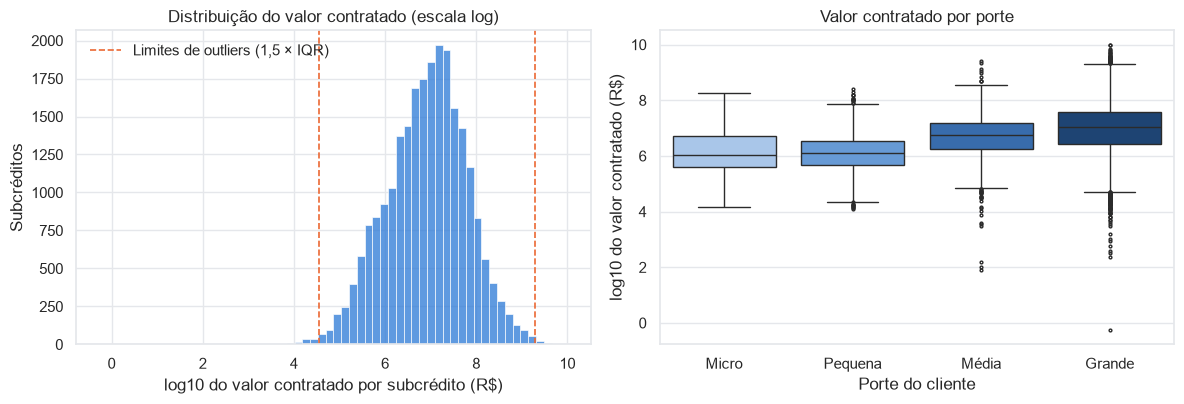

In [7]:
fig = viz.est_distribuicao_valores(df)
plt.show()

**Interpretação.** O valor por subcrédito é muito assimétrico: a mediana é de R$ 9,2 milhões, a média passa de R$ 51 milhões e o máximo
chega a quase R$ 10 bilhões. Na escala logarítmica a distribuição fica próxima de simétrica, o que justifica usar **medianas** e
correlação de **Spearman** nas análises. Pelo critério de 1,5 × IQR no log, 174 subcréditos são outliers, e eles somam 13,5% do valor
total. Eles foram sinalizados (`flag_outlier_valor`) e mantidos, pois são operações reais de grande porte.

## 5. RQ1: evolução temporal do valor contratado

In [8]:
anual = etl.resumo_anual(df)
anual["valor_bi"] = anual["valor_contratado"] / 1e9
anual[["ano", "contratos", "subcreditos", "valor_bi"]].set_index("ano").T

ano,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
contratos,329.00,249.00,300.00,361.00,345.00,446.00,456.00,578.00,527.00,497.00,555.00,568.00,541.00,405.00,220.00,204.00,279.00,113.00,180.00,184.00,221.00,194.00,351.00,351.00,275.00
subcreditos,878.00,459.00,632.00,588.00,747.00,"1,173.00","1,137.00","1,842.00","1,529.00","1,477.00","1,850.00","1,592.00","1,353.00","1,184.00",556.00,771.00,603.00,291.00,490.00,611.00,549.00,558.00,978.00,"1,334.00",853.00
valor_bi,15.61,9.74,13.55,16.86,28.01,47.28,41.72,98.99,60.01,67.49,129.55,86.82,75.61,40.73,24.10,31.46,51.24,29.48,37.60,34.83,47.23,43.85,94.47,73.50,40.47


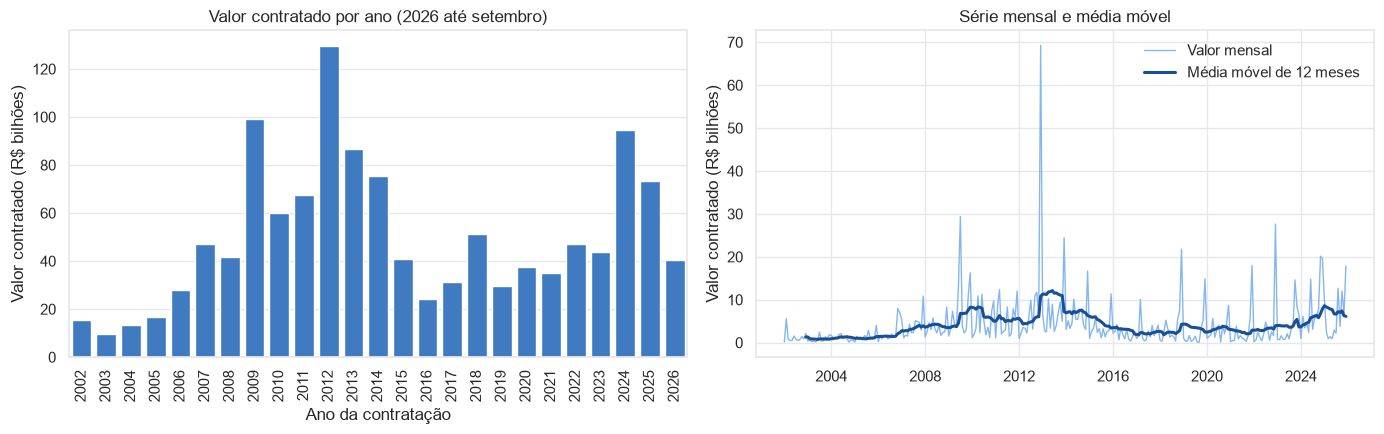

In [9]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))
completos = anual[anual["ano"] <= etl.ANO_COMPLETO_FINAL]
sns.barplot(data=anual, x="ano", y="valor_bi", color=viz.AZUL, ax=eixos[0])
eixos[0].set_xlabel("Ano da contratação")
eixos[0].set_ylabel("Valor contratado (R$ bilhões)")
eixos[0].set_title("Valor contratado por ano (2026 até setembro)")
eixos[0].tick_params(axis="x", rotation=90)

mensal = etl.resumo_mensal(df[df["ano"] <= etl.ANO_COMPLETO_FINAL])
eixos[1].plot(mensal["ano_mes"], mensal["valor_contratado_reais"] / 1e9, color=viz.AZUL_CLARO, linewidth=1, label="Valor mensal")
eixos[1].plot(mensal["ano_mes"], mensal["media_movel_12m"] / 1e9, color=viz.AZUL_ESCURO, linewidth=2.2, label="Média móvel de 12 meses")
eixos[1].set_ylabel("Valor contratado (R$ bilhões)")
eixos[1].set_title("Série mensal e média móvel")
eixos[1].legend(frameon=False)
fig.tight_layout()
plt.show()

In [10]:
ind = etl.calcular_indicadores(df)
print(f"Pico anual: {ind['ano_pico']} (R$ {ind['valor_pico'] / 1e9:.1f} bi) | vale pós-2012: {ind['ano_vale']} (R$ {ind['valor_vale'] / 1e9:.1f} bi)")
for nome, chave in [("2002-2008", "media_2002_2008"), ("2009-2014", "media_2009_2014"), ("2015-2019", "media_2015_2019"), ("2020-2025", "media_2020_2025")]:
    print(f"Média anual {nome}: R$ {ind[chave] / 1e9:.1f} bi")
print(f"Mês de maior valor: {ind['mes_pico']:%m/%Y} (R$ {ind['valor_mes_pico'] / 1e9:.1f} bi); maior cliente do mês: {ind['cliente_mes_pico']} (R$ {ind['valor_cliente_mes_pico'] / 1e9:.1f} bi)")
print(f"Participação de out-dez no valor: {ind['participacao_quarto_trimestre']:.1%}")
print(f"Out-dez acima de 25% em {ind['anos_q4_acima_uniforme']} dos {ind['anos_completos']} anos completos; sem 2012: {ind['quarto_trimestre_sem_2012']:.1%}")
print(f"Dezembro: {ind['participacao_dezembro_valor']:.1%} do valor e {ind['participacao_dezembro_subcreditos']:.1%} dos subcréditos")

Pico anual: 2012 (R$ 129.5 bi) | vale pós-2012: 2016 (R$ 24.1 bi)
Média anual 2002-2008: R$ 24.7 bi
Média anual 2009-2014: R$ 86.4 bi
Média anual 2015-2019: R$ 35.4 bi
Média anual 2020-2025: R$ 55.2 bi
Mês de maior valor: 12/2012 (R$ 69.3 bi); maior cliente do mês: NORTE ENERGIA S/A (R$ 16.8 bi)
Participação de out-dez no valor: 46.9%
Out-dez acima de 25% em 22 dos 24 anos completos; sem 2012: 44.4%
Dezembro: 28.0% do valor e 18.7% dos subcréditos


**Interpretação (RQ1).** O valor contratado **não segue uma tendência única**: há quatro regimes. A média anual vai de R$ 24,7 bi em
2002-2008 para R$ 86,4 bi em 2009-2014, com pico de **R$ 129,5 bi em 2012**; cai para R$ 35,4 bi em 2015-2019 (vale de R$ 24,1 bi em
2016) e se recupera para R$ 55,2 bi em 2020-2025, com R$ 94,5 bi em 2024. O mês mais alto da série, dezembro de 2012 (R$ 69,3 bi),
é dominado por um único cliente, a Norte Energia S/A (R$ 16,8 bi), o que mostra como poucas operações movem a série. Há ainda uma
marca sazonal: **46,9% do valor** é contratado de outubro a dezembro (22 dos 24 anos completos passam de 25%, e sem 2012 a participação segue em 44,4%); dezembro sozinho tem 28,0% do valor e 18,7% dos subcréditos. A base descreve *o que* foi contratado, não *por quê*; atribuir
os regimes a políticas ou a ciclos econômicos exigiria dados externos.

## 6. RQ2: concentração do valor contratado

In [11]:
for coluna in ["porte_do_cliente", "setor_bndes", "regiao"]:
    resumo = etl.resumo_por(df, coluna)
    resumo["valor_bi"] = resumo["valor_contratado"] / 1e9
    resumo["mediana_mi"] = resumo["mediana_subcredito"] / 1e6
    resumo["participacao"] = resumo["participacao"] * 100
    display(resumo[[coluna, "subcreditos", "valor_bi", "participacao", "mediana_mi"]].round(1))

,porte_do_cliente,subcreditos,valor_bi,participacao,mediana_mi
0,GRANDE,20785,"1,194.60",96.30,11.10
2,MÉDIA,1728,36.80,3.00,5.60
3,PEQUENA,837,4.80,0.40,1.30
1,MICRO,685,4.00,0.30,1.10


,setor_bndes,subcreditos,valor_bi,participacao,mediana_mi
3,INFRAESTRUTURA,9703,748.20,60.30,15.60
2,INDUSTRIA,8533,288.50,23.30,7.20
1,COMERCIO/SERVICOS,4902,179.90,14.50,4.50
0,AGROPECUÁRIA,897,23.60,1.90,8.50


,regiao,subcreditos,valor_bi,participacao,mediana_mi
4,Sudeste,10199,454.30,36.60,7.00
3,Sem UF única,2608,232.60,18.80,14.00
1,Nordeste,3504,192.10,15.50,14.80
5,Sul,4857,153.90,12.40,7.90
0,Centro-Oeste,1888,109.70,8.80,11.50
2,Norte,979,97.50,7.90,15.00


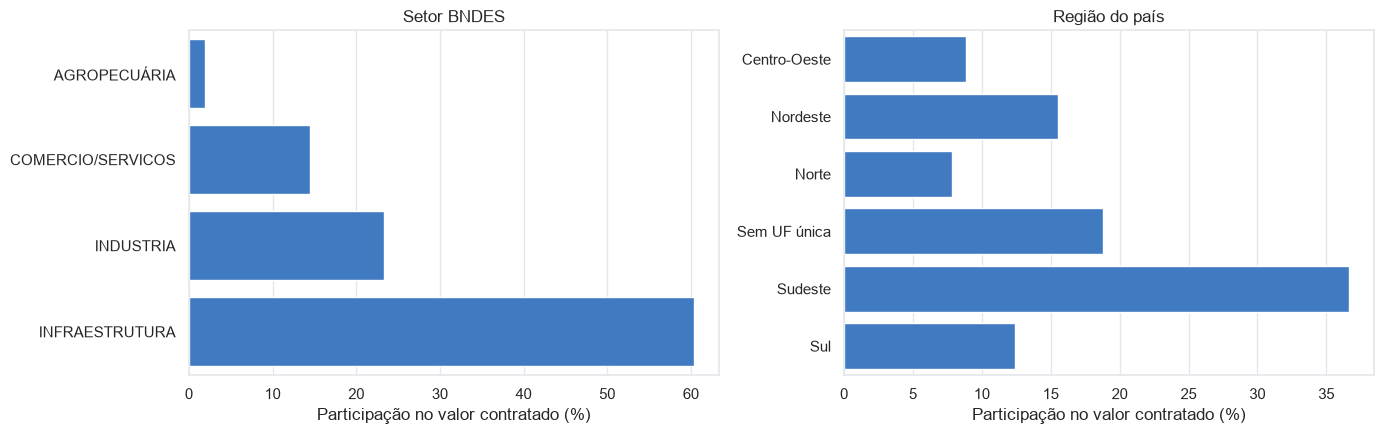

In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))
for eixo, coluna, titulo in zip(eixos, ["setor_bndes", "regiao"], ["Setor BNDES", "Região do país"]):
    resumo = etl.resumo_por(df, coluna)
    sns.barplot(data=resumo, y=coluna, x=resumo["participacao"] * 100, color=viz.AZUL, ax=eixo)
    eixo.set_xlabel("Participação no valor contratado (%)")
    eixo.set_ylabel("")
    eixo.set_title(titulo)
fig.tight_layout()
plt.show()

Clientes: 4.429 | Gini: 0.857 | top 10 clientes: 15.5% | top 1% dos clientes: 34.9%
cliente
PETROLEO BRASILEIRO S A PETROBRAS   33.70
ESTADO DE SAO PAULO                 31.50
NORTE ENERGIA S/A                   23.40
VALE S.A.                           20.40
SUZANO S.A.                         19.70


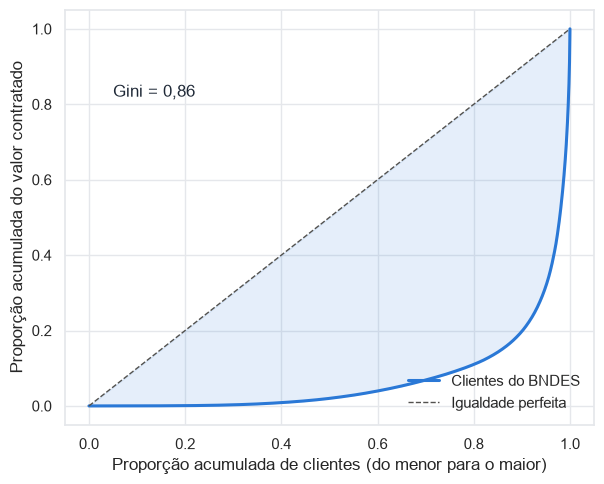

In [13]:
por_cliente = df.groupby("cnpj", observed=True)[valor].sum()
print(f"Clientes: {len(por_cliente):,} | Gini: {etl.gini(por_cliente):.3f} | top 10 clientes: {etl.participacao_topo(por_cliente, 10):.1%} | top 1% dos clientes: {etl.participacao_topo(por_cliente, int(len(por_cliente) * 0.01)):.1%}".replace(",", "."))
print((df.groupby("cliente", observed=True)[valor].sum().nlargest(5) / 1e9).round(1).to_string())
viz.est_lorenz(df)
plt.show()

**Interpretação (RQ2).** A concentração é forte em todas as dimensões. Por **porte**, clientes grandes ficam com 96,3% do valor (média
de R$ 11,1 mi por subcrédito contra R$ 1,1 mi das microempresas). Por **setor**, infraestrutura responde por 60,3%, indústria por
23,3%, comércio e serviços por 14,5% e agropecuária por 1,9%. Por **região**, o Sudeste lidera com 36,6% (SP 18,4% e RJ 11,9%), mas
18,8% do valor está em operações sem UF única (código `IE`), como as de empresas com plantas em vários estados. Entre os **clientes**, o
Gini é 0,86: 1% dos clientes (44) concentra 34,9% do valor, e os dez maiores, 15,5%. A maior concentração relativa aparece no porte
e no setor, não em uma região específica.

## 7. RQ3: valor, prazo e juros

In [14]:
nao_reemb = etl.nao_reembolsavel(df)
print(f"Não reembolsáveis: {nao_reemb.mean():.1%} das linhas e {df.loc[nao_reemb, valor].sum() / df[valor].sum():.2%} do valor")
print("Nas não reembolsáveis, juros e prazos de amortização medianos:", df.loc[nao_reemb, ["juros", "prazo_amortizacao_meses"]].median().to_dict())
colunas = [valor, "juros", "prazo_carencia_meses", "prazo_amortizacao_meses"]
print("\nCorrelação de Spearman, todas as operações:")
display(df[colunas].astype(float).corr(method="spearman").round(2))
print("Correlação de Spearman, só operações reembolsáveis:")
display(df.loc[~nao_reemb, colunas].astype(float).corr(method="spearman").round(2))

Não reembolsáveis: 6.7% das linhas e 0.97% do valor
Nas não reembolsáveis, juros e prazos de amortização medianos: {'juros': 0.0, 'prazo_amortizacao_meses': 0.0}

Correlação de Spearman, todas as operações:


,valor_contratado_reais,juros,prazo_carencia_meses,prazo_amortizacao_meses
valor_contratado_reais,1.00,0.12,0.16,0.27
juros,0.12,1.00,0.11,0.21
prazo_carencia_meses,0.16,0.11,1.00,0.30
prazo_amortizacao_meses,0.27,0.21,0.30,1.00


Correlação de Spearman, só operações reembolsáveis:


,valor_contratado_reais,juros,prazo_carencia_meses,prazo_amortizacao_meses
valor_contratado_reais,1.00,0.03,0.08,0.21
juros,0.03,1.00,-0.08,0.04
prazo_carencia_meses,0.08,-0.08,1.00,0.15
prazo_amortizacao_meses,0.21,0.04,0.15,1.00


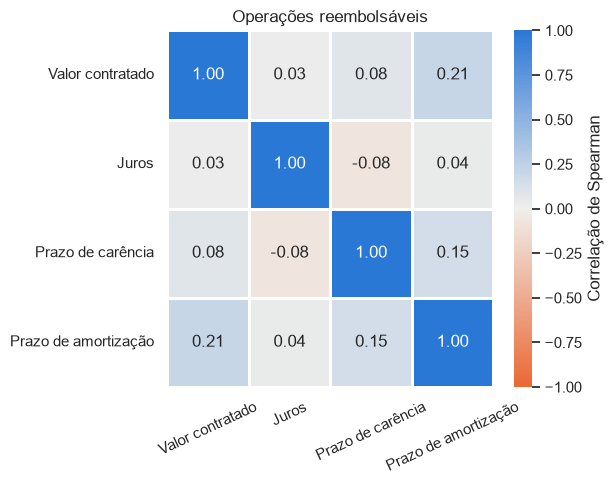

In [15]:
viz.est_correlacao(df)
plt.show()

In [16]:
reemb = df[~nao_reemb]
tabela = reemb.groupby("inovacao", observed=True).agg(
    subcreditos=(valor, "size"),
    valor_mediano_mi=(valor, lambda s: s.median() / 1e6),
    juros_mediano=("juros", "median"),
    carencia_mediana=("prazo_carencia_meses", "median"),
    amortizacao_mediana=("prazo_amortizacao_meses", "median"),
)
tabela

,subcreditos,valor_mediano_mi,juros_mediano,carencia_mediana,amortizacao_mediana
inovacao,,,,,
NÃO,20787,10.93,2.56,21.00,84.00
SIM,1632,3.92,2.70,24.00,60.00


**Interpretação (RQ3).** Misturar tudo esconde um efeito de composição: as operações **não reembolsáveis** (6,7% das linhas, 1% do
valor) têm juros e prazos iguais a zero por definição, o que infla a correlação geral entre valor e prazo de amortização (0,27).
Restringindo às **reembolsáveis**, as relações são fracas: valor × amortização 0,21, valor × carência 0,08 e valor × juros 0,03,
ou seja, o tamanho da operação quase não explica o custo. No apoio à **inovação**, o valor mediano é menor (R$ 3,9 mi contra R$ 10,9 mi),
a amortização é mais curta (60 contra 84 meses) e os juros medianos ficam um pouco acima (2,70% contra 2,56% a.a.). A associação é
descritiva, pois porte, setor e instrumento financeiro também diferem entre os grupos.

## 8. Análise de sensibilidade e limitações

In [17]:
print(f"Linhas repetidas sinalizadas: {df['flag_linha_repetida'].sum()} = {ind['valor_linhas_repetidas']:.2%} do valor")
print(f"Outliers de valor sinalizados: {df['flag_outlier_valor'].sum()} = {ind['valor_outliers']:.2%} do valor")
print(f"Desembolso acima do contratado: {ind['desembolso_acima']:.1%} das linhas (o dicionário do BNDES atribui isso à correção por indexador)")
print(f"Taxa de execução global (desembolsado / contratado): {ind['taxa_execucao']:.1%}")
sem_repetidas = df[~df["flag_linha_repetida"]]
print(f"Total contratado: R$ {df[valor].sum() / 1e9:,.1f} bi; sem as linhas repetidas: R$ {sem_repetidas[valor].sum() / 1e9:,.1f} bi")

Linhas repetidas sinalizadas: 408 = 1.62% do valor
Outliers de valor sinalizados: 174 = 13.48% do valor
Desembolso acima do contratado: 25.3% das linhas (o dicionário do BNDES atribui isso à correção por indexador)
Taxa de execução global (desembolsado / contratado): 77.8%
Total contratado: R$ 1,240.2 bi; sem as linhas repetidas: R$ 1,220.1 bi


Excluir as linhas repetidas mudaria o total em apenas 1,6%, e nenhuma conclusão deste caderno se altera. As limitações principais são:
(i) a base cobre só as operações **não automáticas**, não o total de financiamentos do BNDES; (ii) 2026 está incompleto (até 30/09),
então as comparações usam 2002-2025; (iii) os valores são nominais, sem correção pela inflação; (iv) a região é derivada da UF, e
18,8% do valor não tem UF única.

## 9. Conclusão

O valor contratado em operações não automáticas do BNDES passa por regimes distintos entre 2002 e 2025, com pico em 2012 e vale em 2016,
e é fortemente concentrado em clientes grandes, em infraestrutura e no Sudeste. Nas operações reembolsáveis, valor, prazo e juros se
relacionam de forma fraca. O pipeline é determinístico e reproduzível (`python -m src.etl`), preserva todas as linhas e registra cada
decisão de tratamento em `data/processed/relatorio_etl.json`.